
 OBSERVABLE BEHAVIOR PROBABILITY P(B_t | S_t)
-> P(B_t = 1 | S_t = 1) : 0.95
   (If the brain is in a Violation state, there is a 95% chance we observe actual Overspeeding)
-> P(B_t = 1 | S_t = 0) : 0.05
   (If the brain is in Compliance, there is only a 5% chance of an accidental violation)

 REQUIRED PARAMETER SET

[DAYTIME MODEL: 'Late' Antecedent]
1. Transition Probability P(S=1|S=0) : 0.155
2. Sensitivity to stimulus (Beta)    : -13.23
3. Decay/Recovery rate (Delta)       : 9.75
4. Learning rate (Alpha)             : N/A (Using Markov Model)
5. Noise parameter (Epsilon)         : 0.05

[NIGHTTIME MODEL: 'Empty Road' Antecedent]
1. Transition Probability P(S=1|S=0) : 0.369
2. Sensitivity to stimulus (Beta)    : -3.05
3. Decay/Recovery rate (Delta)       : 5.22
4. Learning rate (Alpha)             : N/A (Using Markov Model)
5. Noise parameter (Epsilon)         : 0.05

 GOODNESS OF FIT METRICS
[DAYTIME]   Log-Likelihood: -413.25 | AIC Score: 830.50
[NIGHTTIME] Log-Likelihood: -714.6

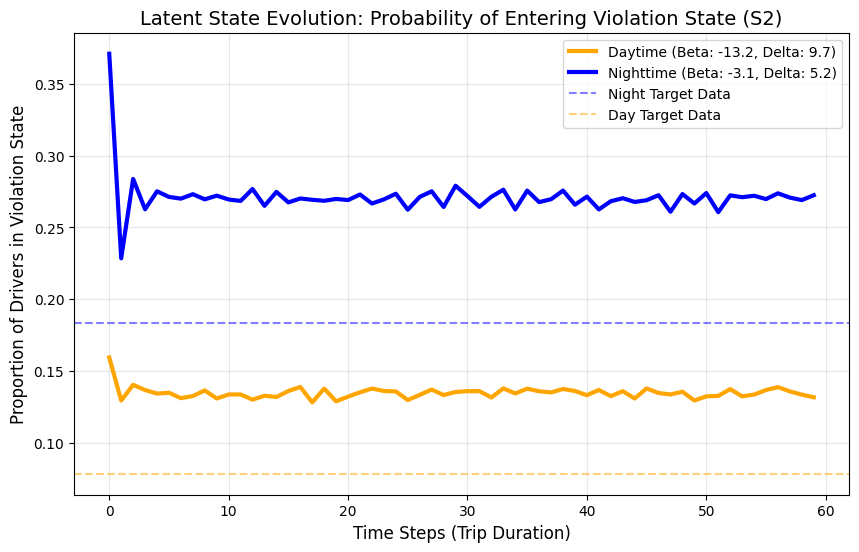

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# ---------------------------------------------------------
# 1. CORE MATH FUNCTIONS
# ---------------------------------------------------------
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def calculate_loss(params, x_stimulus, target_violation_rate):
    """The Auto-Tuner scorekeeper (Negative Log-Likelihood)"""
    beta, delta = params
    p_predicted = sigmoid(beta * x_stimulus - delta * target_violation_rate)
    loss = - (target_violation_rate * np.log(p_predicted + 1e-9) +
              (1 - target_violation_rate) * np.log(1 - p_predicted + 1e-9))
    return loss

def simulate_trip(agents, steps, beta, delta, x_stimulus, noise_epsilon):
    """The 60-minute trip simulator"""
    states = np.zeros(agents)
    s2_history = []

    for t in range(steps):
        # Adding the noise parameter (epsilon) to the simulation
        noise = np.random.normal(0, noise_epsilon, agents)
        probability = sigmoid(beta * x_stimulus - delta * states + noise)

        states = (np.random.rand(agents) < probability).astype(int)
        s2_history.append(np.mean(states))

    return s2_history

def calculate_aic_ll(beta, delta, x_stimulus, target_rate, sample_size=1500):
    """Calculates Log-Likelihood and AIC for the report"""
    p_predicted = sigmoid(beta * x_stimulus - delta * target_rate)
    ll = sample_size * (target_rate * np.log(p_predicted + 1e-9) +
                       (1 - target_rate) * np.log(1 - p_predicted + 1e-9))
    k = 2
    aic = 2 * k - 2 * ll
    return ll, aic

# ---------------------------------------------------------
# 2. REAL DATA (1500-Unit Scale)
# ---------------------------------------------------------
x_night = 264 / 1500          # Empty Road antecedent
target_night = 275 / 1500     # Behaviour shown = overspeeding

x_day = 192 / 1500            # Late antecedent
target_day = 118 / 1500       # Behaviour shown = rule violations during daytime



# The noise parameter (epsilon) representing human randomness
NOISE_EPSILON = 0.05
# ---------------------------------------------------------
print("\n" + "="*50)
print(" OBSERVABLE BEHAVIOR PROBABILITY P(B_t | S_t)")
print("="*50)

# The behavior emission probabilities based on the noise parameter
prob_b1_given_s1 = 1.0 - NOISE_EPSILON
prob_b1_given_s0 = NOISE_EPSILON

print(f"-> P(B_t = 1 | S_t = 1) : {prob_b1_given_s1:.2f}")
print("   (If the brain is in a Violation state, there is a 95% chance we observe actual Overspeeding)")
print(f"-> P(B_t = 1 | S_t = 0) : {prob_b1_given_s0:.2f}")
print("   (If the brain is in Compliance, there is only a 5% chance of an accidental violation)")



# ---------------------------------------------------------
# 3. RUNS THE AUTO-TUNER & PRINTS PARAMETERS IMMEDIATELY
# ---------------------------------------------------------
print("\n" + "="*50)
print(" REQUIRED PARAMETER SET")
print("="*50)

initial_guess = [1.0, 1.0]

# --- TUNE DAYTIME ---
day_result = minimize(calculate_loss, initial_guess, args=(x_day, target_day))
best_beta_day, best_delta_day = day_result.x
# Calculate the transition probability for a driver currently in State 0
p_transition_day = sigmoid(best_beta_day * x_day - best_delta_day * 0)

print("\n[DAYTIME MODEL: 'Late' Antecedent]")
print(f"1. Transition Probability P(S=1|S=0) : {p_transition_day:.3f}")
print(f"2. Sensitivity to stimulus (Beta)    : {best_beta_day:.2f}")
print(f"3. Decay/Recovery rate (Delta)       : {best_delta_day:.2f}")
print(f"4. Learning rate (Alpha)             : N/A (Using Markov Model)")
print(f"5. Noise parameter (Epsilon)         : {NOISE_EPSILON}")



# --- TUNE NIGHTTIME --
night_result = minimize(calculate_loss, initial_guess, args=(x_night, target_night))
best_beta_night, best_delta_night = night_result.x
# Calculate the transition probability for a driver currently in State 0
p_transition_night = sigmoid(best_beta_night * x_night - best_delta_night * 0)

print("\n[NIGHTTIME MODEL: 'Empty Road' Antecedent]")
print(f"1. Transition Probability P(S=1|S=0) : {p_transition_night:.3f}")
print(f"2. Sensitivity to stimulus (Beta)    : {best_beta_night:.2f}")
print(f"3. Decay/Recovery rate (Delta)       : {best_delta_night:.2f}")
print(f"4. Learning rate (Alpha)             : N/A (Using Markov Model)")
print(f"5. Noise parameter (Epsilon)         : {NOISE_EPSILON}")



# ---------------------------------------------------------
# 4. RUNS THE TRIP SIMULATOR USING THE VARIABLES
# ---------------------------------------------------------
AGENTS = 10000
STEPS = 60

# The variables best_beta_day, etc. are used here further down in the code
day_trajectory = simulate_trip(AGENTS, STEPS, best_beta_day, best_delta_day, x_day, NOISE_EPSILON)
night_trajectory = simulate_trip(AGENTS, STEPS, best_beta_night, best_delta_night, x_night, NOISE_EPSILON)



# ---------------------------------------------------------
# 5. CALCULATES EVALUATION METRICS (AIC & LL)
# ---------------------------------------------------------
ll_day, aic_day = calculate_aic_ll(best_beta_day, best_delta_day, x_day, target_day)
ll_night, aic_night = calculate_aic_ll(best_beta_night, best_delta_night, x_night, target_night)

print("\n" + "="*50)
print(" GOODNESS OF FIT METRICS")
print("="*50)
print(f"[DAYTIME]   Log-Likelihood: {ll_day:.2f} | AIC Score: {aic_day:.2f}")
print(f"[NIGHTTIME] Log-Likelihood: {ll_night:.2f} | AIC Score: {aic_night:.2f}")
print("="*50)

# --- CALCULATES EQUILIBRIUM CONDITION (S*) ---
# Formula: S* = (Beta / Delta) * X
equilibrium_day = (best_beta_day / best_delta_day) * x_day
equilibrium_night = (best_beta_night / best_delta_night) * x_night

print("\n" + "="*50)
print(" EQUILIBRIUM CONDITION (S*)")
print("="*50)
print(f"[DAYTIME]   Equilibrium (S*): {equilibrium_day:.3f}")
print(f"[NIGHTTIME] Equilibrium (S*): {equilibrium_night:.3f}")
# Notice how the Nighttime equilibrium is massively higher because of the low Delta (decay rate)
print("="*50)



# ---------------------------------------------------------
# 6. PLOTS THE GRAPH
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
plt.plot(day_trajectory, label=f'Daytime (Beta: {best_beta_day:.1f}, Delta: {best_delta_day:.1f})', color='orange', lw=3)
plt.plot(night_trajectory, label=f'Nighttime (Beta: {best_beta_night:.1f}, Delta: {best_delta_night:.1f})', color='blue', lw=3)

plt.title('Latent State Evolution: Probability of Entering Violation State (S2)', fontsize=14)
plt.xlabel('Time Steps (Trip Duration)', fontsize=12)
plt.ylabel('Proportion of Drivers in Violation State', fontsize=12)
plt.axhline(y=target_night, color='blue', linestyle='--', alpha=0.5, label='Night Target Data')
plt.axhline(y=target_day, color='orange', linestyle='--', alpha=0.5, label='Day Target Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [2]:
import numpy as np
from scipy.optimize import minimize
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score

def sigmoid(x): return 1 / (1 + np.exp(-x))

def calc_loss(params, x_val, target_rate):
    beta, delta = params
    p_pred = sigmoid(beta * x_val - delta * target_rate)
    loss = - (target_rate * np.log(p_pred + 1e-9) + (1 - target_rate) * np.log(1 - p_pred + 1e-9))
    return loss

def run_cross_validation_ml(x_trigger, total_drivers, total_violations, model_name):
    data = np.zeros(total_drivers)
    data[:total_violations] = 1
    np.random.shuffle(data)

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    accuracies = []

    for train_index, test_index in kf.split(data):
        train_data, test_data = data[train_index], data[test_index]
        train_rate = np.mean(train_data)

        # 1. Trains the model
        res = minimize(calc_loss, [1.0, 1.0], args=(x_trigger, train_rate))
        beta_train, delta_train = res.x

        # 2. ML Prediction
        # Calculates the final mathematical probability of breaking the rule
        final_prob = sigmoid(beta_train * x_trigger - delta_train * train_rate)

        # ML Logic: If chance is > 50%, predict 1. If < 50%, predict 0.
        if final_prob > 0.5:
            predictions = np.ones(len(test_data))
        else:
            predictions = np.zeros(len(test_data))

        # 3. Calculates Accuracy
        acc = accuracy_score(test_data, predictions) * 100
        accuracies.append(acc)

    avg_acc = np.mean(accuracies)
    print(f"-> {model_name} Model CV Accuracy: {avg_acc:.1f}%")
    return avg_acc

print("="*50)
print(" RUNNING ML CROSS-VALIDATION")
print("="*50)

# Runs for Daytime (1500 drivers, 118 violations)
day_acc = run_cross_validation_ml(192/1500, 1500, 118, "Daytime ('Late')")

# Runs for Nighttime (1500 drivers, 275 violations)
night_acc = run_cross_validation_ml(264/1500, 1500, 275, "Nighttime ('Empty Road')")


 RUNNING ML CROSS-VALIDATION
-> Daytime ('Late') Model CV Accuracy: 92.1%
-> Nighttime ('Empty Road') Model CV Accuracy: 81.7%
